In [1]:
import warnings; warnings.filterwarnings("ignore") # remove scanpy warnings for the tutorial.

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scanpy as sc

In [3]:
import decipher as dc
dc.pl.activate_journal_quality()

In [5]:
color_palette = None

adata = sc.read_h5ad(f"./paul2015data/Paul_etal_15.h5ad")


In [6]:
adata

AnnData object with n_obs × n_vars = 2671 × 1999
    obs: 'paul15_clusters', 'n_counts_all', 'n_counts', 'louvain', 'cell_type'
    var: 'n_counts', 'mean', 'std'
    uns: 'cell_type_colors', 'diffmap_evals', 'draw_graph', 'iroot', 'log1p', 'louvain', 'louvain_colors', 'louvain_sizes', 'neighbors', 'paga', 'paul15_clusters_colors', 'pca'
    obsm: 'X_diffmap', 'X_draw_graph_fa', 'X_draw_graph_fr', 'X_pca'
    varm: 'PCs'
    layers: 'raw_count', 'raw_count_int'
    obsp: 'connectivities', 'distances'

In [ ]:
#adata.obs["cell_type"] = adata.obs["paul15_clusters"]

In [7]:
adata.X = adata.layers["raw_count_int"].copy()

Epoch 67 (batch 37/37) | | train elbo: 1278.59 (last epoch: 1278.69) | val ll: 1297.66:   7%|▋         | 67/1000 [01:35<22:06,  1.42s/it]2026-07-06 19:58:22,181 | INFO : Early stopping has been triggered.
2026-07-06 19:58:22,246 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-07-06 19:58:22,247 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-07-06 19:58:22,250 | INFO : Saving decipher model with run_id 2026-07-06-19-58-22-fundamental-ash-permutation.


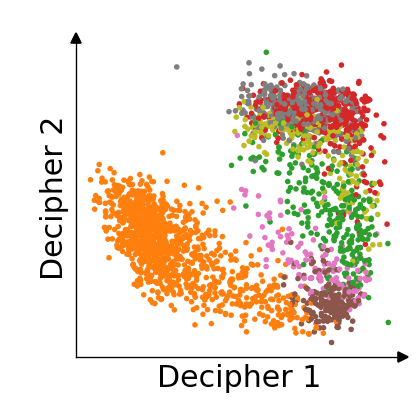

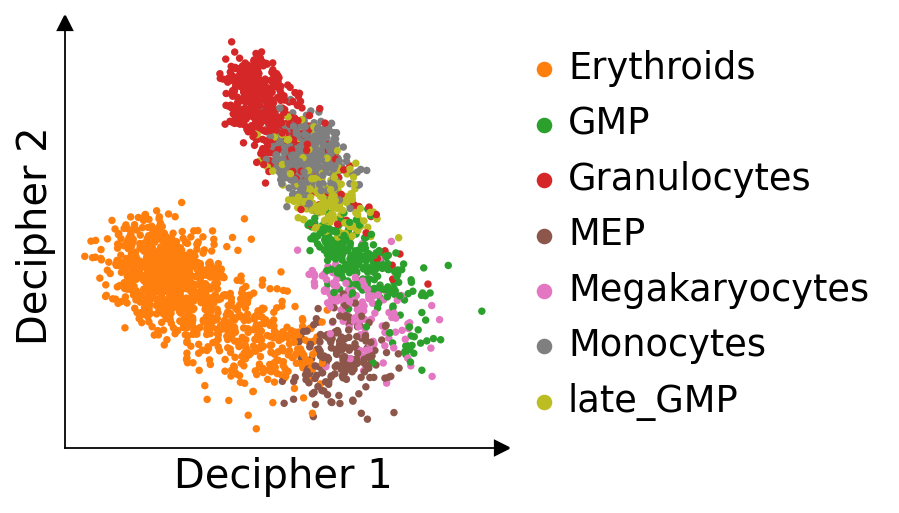

In [8]:
d1, val1 = dc.tl.decipher_train(
    adata, plot_kwargs={"color": "cell_type"}, plot_every_k_epochs=5,
)

In [9]:
adata

AnnData object with n_obs × n_vars = 2671 × 1999
    obs: 'paul15_clusters', 'n_counts_all', 'n_counts', 'louvain', 'cell_type', 'decipher_split'
    var: 'n_counts', 'mean', 'std'
    uns: 'cell_type_colors', 'diffmap_evals', 'draw_graph', 'iroot', 'log1p', 'louvain', 'louvain_colors', 'louvain_sizes', 'neighbors', 'paga', 'paul15_clusters_colors', 'pca', 'decipher'
    obsm: 'X_diffmap', 'X_draw_graph_fa', 'X_draw_graph_fr', 'X_pca', 'decipher_v', 'decipher_z'
    varm: 'PCs'
    layers: 'raw_count', 'raw_count_int'
    obsp: 'connectivities', 'distances'

In [10]:
import numpy as np

z = adata.obsm["decipher_z"]
v = adata.obsm["decipher_v"]

np.savez("decipher_embeddings.npz", z=z, v=v)

In [11]:
print(z.shape, v.shape)

(2671, 10) (2671, 2)


In [24]:
!pip install "matplotlib==3.7.3"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 165.4 MB/s  0:00:00
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.11.0
    Uninstalling matplotlib-3.11.0:
      Successfully uninstalled matplotlib-3.11.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
scanpy 1.11.5 requires matplotlib>=3.7.5, but you have matplotlib 3.7.3 which is incompatible.


In [9]:
!pip install "ipython==8.12.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 796.4/796.4 kB 38.8 MB/s  0:00:00
  Attempting uninstall: ipython
    Found existing installation: ipython 9.15.0
    Uninstalling ipython-9.15.0:
      Successfully uninstalled ipython-9.15.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ipython]m2/3 [ipython]


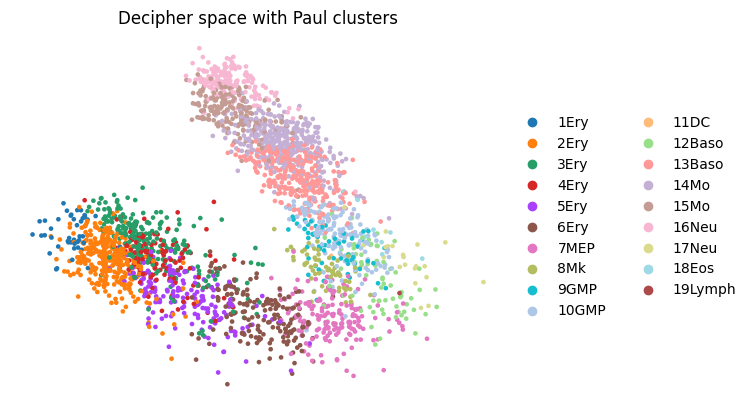

In [2]:
# Plot cells in Decipher space, colored by Paul clusters -- no training required.
# Loads the Paul data + precomputed Decipher embeddings from disk.
import numpy as np
import scanpy as sc

DATA_DIR = "/home/elicanter/datasets/paul2015data"

adata = sc.read_h5ad(f"{DATA_DIR}/Paul_etal_15.h5ad")

emb = np.load(f"{DATA_DIR}/decipher_embeddings.npz")
adata.obsm["decipher_v"] = emb["v"]  # 2D visualization space
adata.obsm["decipher_z"] = emb["z"]  # 10D latent space

sc.pl.embedding(
    adata,
    basis="decipher_v",
    color="paul15_clusters",
    title="Decipher space with Paul clusters",
    frameon=False,
)